
# 06 – AML vs Deep Learning Comparison

## Flight Club – Flight Delay Prediction

### Objective

This notebook compares traditional machine learning models with the Deep Learning Embedding MLP model developed for flight delay prediction.

The models evaluated include:

1. Logistic Regression
2. XGBoost
3. Embedding + MLP

### Comparison Objectives

- Compare classification performance across AML and DL models.
- Evaluate ROC-AUC and PR-AUC.
- Compare precision, recall, F1-score and calibration.
- Investigate the contribution of learned categorical embeddings.
- Compare model complexity, training time and inference time.
- Identify the strengths and limitations of each approach.

### Experimental Guidelines

All models must use the same target definition, chronological data split and test observations.

The test dataset must remain untouched during model selection and experimentation.

The final comparison will be based on actual experimental results rather than assumed model superiority.



In [29]:
import os
import json
import zipfile
import time
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Libraries imported successfully!")
print("PyTorch:", torch.__version__)
print("Device:", device)

Libraries imported successfully!
PyTorch: 2.14.1+cpu
Device: cpu


In [30]:
os.makedirs("project_inputs", exist_ok=True)
os.makedirs("comparison_results", exist_ok=True)
os.makedirs("comparison_plots", exist_ok=True)

print("Project directories created successfully!")

Project directories created successfully!


In [31]:
# Extract training results
with zipfile.ZipFile(
    "DL_Training_Results.zip", "r"
) as zip_ref:

    zip_ref.extractall("project_inputs/training")


# Extract evaluation results
with zipfile.ZipFile(
    "DL_Evaluation_Results.zip", "r"
) as zip_ref:

    zip_ref.extractall("project_inputs/evaluation")


print("DL files extracted successfully!")

DL files extracted successfully!


In [32]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
for root, dirs, files_list in os.walk("project_inputs"):

    for filename in files_list:

        print(os.path.join(root, filename))

project_inputs/evaluation/test_calibration_curve.png
project_inputs/evaluation/test_confusion_matrix.png
project_inputs/evaluation/validation_pr_curve.png
project_inputs/evaluation/validation_metrics.csv
project_inputs/evaluation/test_predictions.csv
project_inputs/evaluation/embedding_ablation_results.csv
project_inputs/evaluation/final_evaluation.json
project_inputs/evaluation/test_metrics_comparison.csv
project_inputs/evaluation/inference_time_comparison.csv
project_inputs/evaluation/validation_confusion_matrix.png
project_inputs/evaluation/validation_roc_curve.png
project_inputs/evaluation/threshold_config.json
project_inputs/evaluation/test_pr_curve.png
project_inputs/evaluation/validation_calibration_curve.png
project_inputs/evaluation/test_roc_curve.png
project_inputs/evaluation/ablation_checkpoints/without_destination.pth
project_inputs/evaluation/ablation_checkpoints/without_all_embeddings.pth
project_inputs/evaluation/ablation_checkpoints/full_model.pth
project_inputs/evaluat


## 4. Dataset and Experimental Consistency

Before comparing the models, we verify that all experiments use a consistent target definition and chronological data split.

The target variable is `delayed`, and the final test period consists of November and December 2013.

Comparing models on different test observations could produce misleading conclusions. Therefore, test-row consistency must be established before interpreting the performance differences.


In [34]:
data = torch.load(
    "dl_data.pt",
    map_location="cpu",
    weights_only=False
)

print("Available dataset keys:")
print(data.keys())

for key, value in data.items():

    if isinstance(value, torch.Tensor):
        print(
            key,
            "Shape:", tuple(value.shape),
            "Dtype:", value.dtype
        )

Available dataset keys:
dict_keys(['X_train_num', 'X_train_cat', 'y_train', 'X_val_num', 'X_val_cat', 'y_val', 'X_test_num', 'X_test_cat', 'y_test', 'numerical_features', 'categorical_features', 'category_maps', 'train_medians', 'scaler_mean', 'scaler_std'])
X_train_num Shape: (217727, 17) Dtype: torch.float32
X_train_cat Shape: (217727, 4) Dtype: torch.int64
y_train Shape: (217727,) Dtype: torch.float32
X_val_num Shape: (55628, 17) Dtype: torch.float32
X_val_cat Shape: (55628, 4) Dtype: torch.int64
y_val Shape: (55628,) Dtype: torch.float32
X_test_num Shape: (53991, 17) Dtype: torch.float32
X_test_cat Shape: (53991, 4) Dtype: torch.int64
y_test Shape: (53991,) Dtype: torch.float32



## 5. Overall Model Performance Comparison

This section compares Logistic Regression, XGBoost and Embedding + MLP using a common set of evaluation metrics.

The comparison includes accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC and Brier score.

The metrics are collected from the final evaluation results of each model.


In [35]:
comparison_data = [
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.617800,
        "Precision": 0.218036,
        "Recall": 0.595127,
        "F1 Score": 0.319147,
        "ROC-AUC": 0.650957,
        "PR-AUC": 0.235002,
        "Brier Score": np.nan
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.700582,
        "Precision": 0.243226,
        "Recall": 0.468530,
        "F1 Score": 0.320219,
        "ROC-AUC": 0.661729,
        "PR-AUC": 0.265836,
        "Brier Score": np.nan
    },
    {
        "Model": "Embedding + MLP",
        "Accuracy": 0.532830,
        "Precision": 0.309938,
        "Recall": 0.708939,
        "F1 Score": 0.431312,
        "ROC-AUC": 0.637669,
        "PR-AUC": 0.361152,
        "Brier Score": 0.181063
    }
]

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Brier Score
0,Logistic Regression,0.617800,0.218036,0.595127,0.319147,0.650957,0.235002,NaN
1,XGBoost,0.700582,0.243226,0.468530,0.320219,0.661729,0.265836,NaN
2,Embedding + MLP,0.532830,0.309938,0.708939,0.431312,0.637669,0.361152,0.181063



## 6. Comparative Performance Visualisation

Visualisations are used to understand differences in model performance.

We compare the models using ROC-AUC, PR-AUC, precision, recall and F1-score.

These visualisations help identify which model provides better discrimination and classification performance.


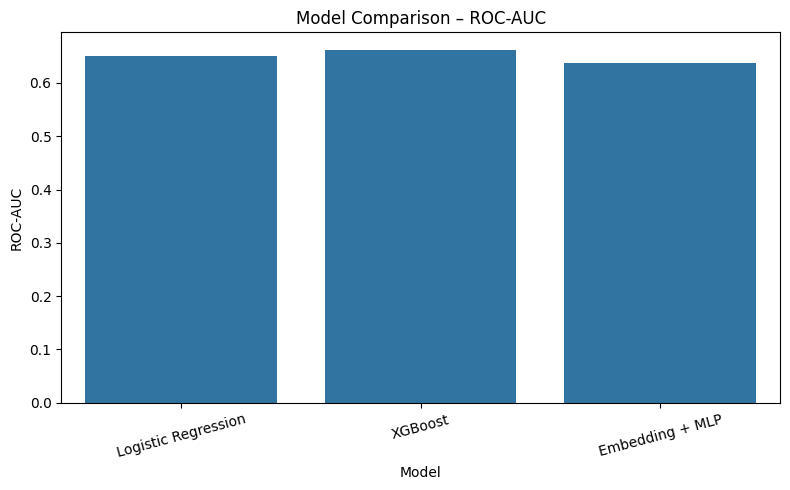

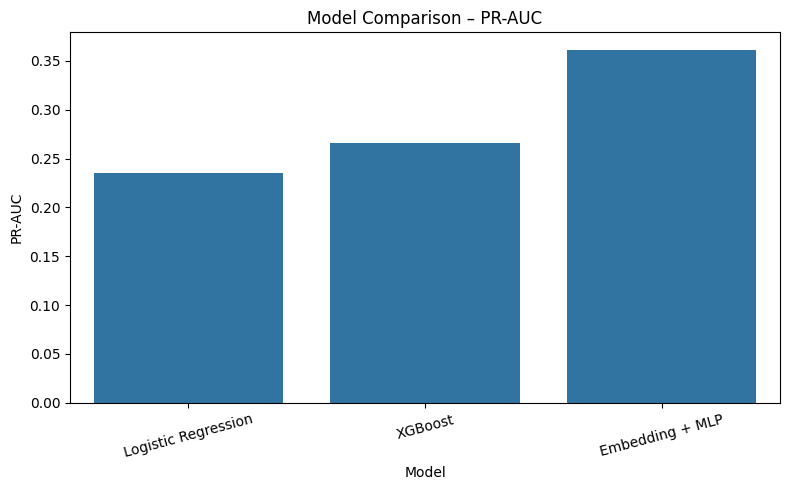

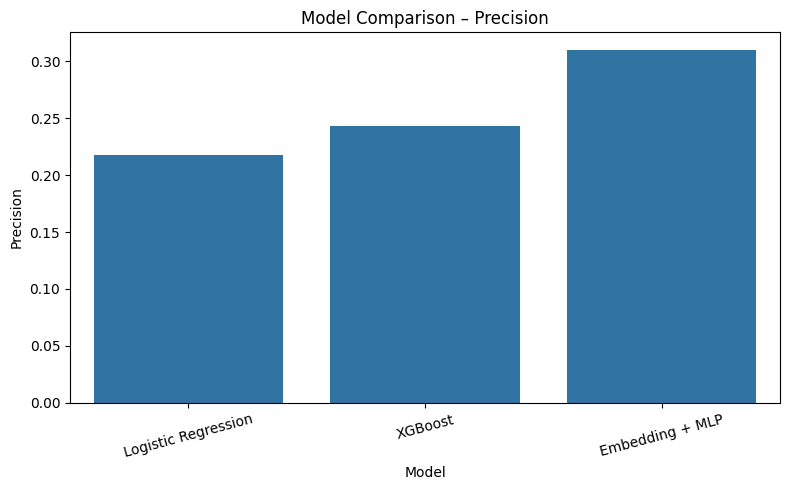

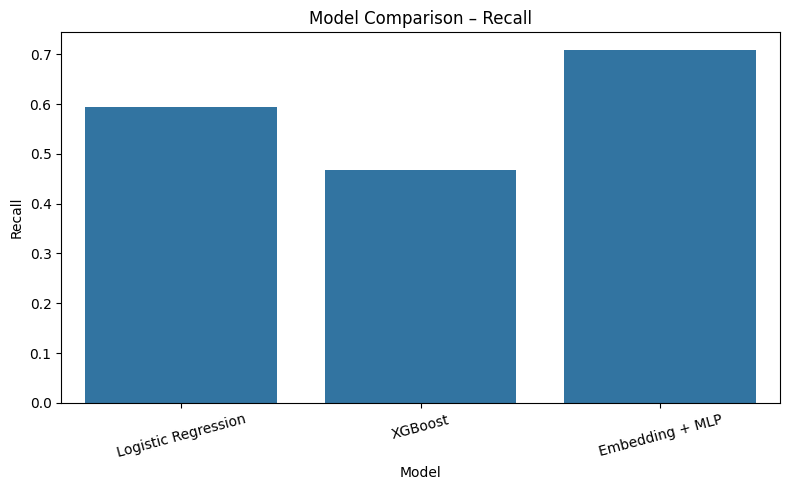

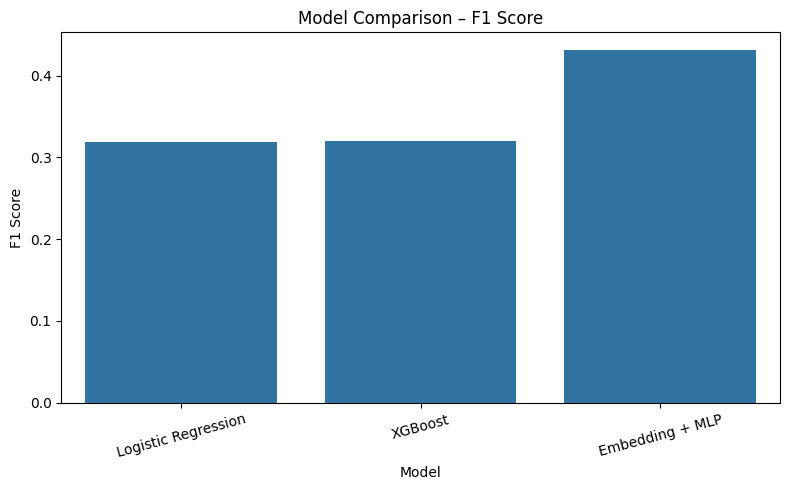

In [36]:
metrics_to_plot = [
    "ROC-AUC",
    "PR-AUC",
    "Precision",
    "Recall",
    "F1 Score"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=comparison_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison – {metric}")
    plt.ylabel(metric)
    plt.xlabel("Model")
    plt.xticks(rotation=15)

    plt.tight_layout()

    plt.savefig(
        f"comparison_plots/{metric.replace(' ', '_')}_comparison.png",
        dpi=300
    )

    plt.show()


## 7. Categorical Embedding Ablation Study

An ablation study is conducted to understand the contribution of learned categorical embeddings to the performance of the Embedding MLP model.

The baseline model uses embeddings for carrier, origin, destination and route.

Individual experiments remove one categorical embedding at a time, while an additional experiment removes all categorical embeddings.

The resulting models are trained and evaluated under consistent experimental conditions.

The objective is to determine which categorical embeddings contribute most to predictive performance.


In [37]:
from model import FlightDelayMLP

# Load the baseline model from the original checkpoint
checkpoint_path = "project_inputs/training/best_model_checkpoint.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

category_sizes = {
    feature: checkpoint["category_sizes"][feature]
    for feature in checkpoint["categorical_features"]
}

embedding_dims = {
    feature: checkpoint["embedding_dims"][feature]
    for feature in checkpoint["categorical_features"]
}

model = FlightDelayMLP(
    numerical_input_dim=checkpoint["numerical_input_dim"],
    category_sizes=category_sizes,
    embedding_dims=embedding_dims,
    hidden_dims=tuple(checkpoint["hidden_dims"]),
    dropout_rates=tuple(checkpoint["dropout_rates"])
)

total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_parameters)

Total trainable parameters: 43142


## 8. Training and Evaluating Embedding Ablation Models

Six model configurations are evaluated to measure the contribution of categorical embeddings.

The full model uses carrier, origin, destination and route embeddings. Four additional models remove one embedding at a time, while the final model removes all categorical embeddings.

All configurations use the same training, validation and test datasets, numerical features, optimiser settings and evaluation metrics.

The validation set is used for early stopping and threshold selection. The test set is reserved for final evaluation.

The experiments report PR-AUC (Average Precision), ROC-AUC, precision, recall, F1-score, Brier Score and training time.

In [38]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load prepared data and original checkpoint
data = torch.load(
    "dl_data.pt",
    map_location="cpu",
    weights_only=False
)

checkpoint = torch.load(
    "project_inputs/training/best_model_checkpoint.pth",
    map_location="cpu",
    weights_only=False
)

all_features = checkpoint["categorical_features"]

class AblationFlightDelayMLP(nn.Module):
    def __init__(
        self,
        numerical_input_dim,
        category_sizes,
        embedding_dims,
        hidden_dims,
        dropout_rates
    ):
        super().__init__()

        self.embeddings = nn.ModuleList([
            nn.Embedding(category_sizes[f], embedding_dims[f])
            for f in category_sizes
        ])

        input_dim = numerical_input_dim + sum(embedding_dims.values())

        layers = []
        previous_dim = input_dim

        for i, hidden_dim in enumerate(hidden_dims):
            layers.append(nn.Linear(previous_dim, hidden_dim))
            layers.append(nn.ReLU())

            dropout = dropout_rates[min(i, len(dropout_rates)-1)]
            layers.append(nn.Dropout(dropout))

            previous_dim = hidden_dim

        layers.append(nn.Linear(previous_dim, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x_num, x_cat):
        parts = [x_num]

        for i, embedding in enumerate(self.embeddings):
            parts.append(embedding(x_cat[:, i]))

        x = torch.cat(parts, dim=1)
        return self.network(x).squeeze(1)


print("Data and checkpoint loaded.")
print("Device:", device)
print("Categorical features:", all_features)

Data and checkpoint loaded.
Device: cpu
Categorical features: ['carrier', 'origin', 'dest', 'route']


In [39]:
X_train_num = data["X_train_num"].float()
X_train_cat = data["X_train_cat"].long()
y_train = data["y_train"].float()

X_val_num = data["X_val_num"].float()
X_val_cat = data["X_val_cat"].long()
y_val = data["y_val"].float()

X_test_num = data["X_test_num"].float()
X_test_cat = data["X_test_cat"].long()
y_test = data["y_test"].float()

train_dataset = TensorDataset(
    X_train_num, X_train_cat, y_train
)

val_dataset = TensorDataset(
    X_val_num, X_val_cat, y_val
)

test_dataset = TensorDataset(
    X_test_num, X_test_cat, y_test
)

experiments = {
    "full_model": all_features,
    "without_carrier": [f for f in all_features if f != "carrier"],
    "without_origin": [f for f in all_features if f != "origin"],
    "without_destination": [f for f in all_features if f != "dest"],
    "without_route": [f for f in all_features if f != "route"],
    "without_all_embeddings": []
}

os.makedirs(
    "project_inputs/evaluation/ablation_checkpoints",
    exist_ok=True
)

print("Experiments:", list(experiments.keys()))

Experiments: ['full_model', 'without_carrier', 'without_origin', 'without_destination', 'without_route', 'without_all_embeddings']


In [40]:
def run_epoch(
    model,
    loader,
    criterion,
    feature_indices,
    optimizer=None
):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_rows = 0

    for x_num, x_cat, y in loader:
        x_num = x_num.to(device)
        x_cat = x_cat[:, feature_indices].to(device)
        y = y.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(x_num, x_cat)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * len(y)
        total_rows += len(y)

    return total_loss / total_rows


def train_ablation_model(name, retained_features):

    # Reset seed for a controlled initialisation
    torch.manual_seed(SEED)

    feature_indices = [
        all_features.index(f)
        for f in retained_features
    ]

    category_sizes = {
        f: checkpoint["category_sizes"][f]
        for f in retained_features
    }

    embedding_dims = {
        f: checkpoint["embedding_dims"][f]
        for f in retained_features
    }

    model = AblationFlightDelayMLP(
        numerical_input_dim=checkpoint["numerical_input_dim"],
        category_sizes=category_sizes,
        embedding_dims=embedding_dims,
        hidden_dims=checkpoint["hidden_dims"],
        dropout_rates=checkpoint["dropout_rates"]
    ).to(device)

    train_loader = DataLoader(
        train_dataset,
        batch_size=checkpoint["batch_size"],
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=checkpoint["batch_size"],
        shuffle=False
    )

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=checkpoint["learning_rate"]
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience = 4
    patience_counter = 0
    max_epochs = 30

    start = time.perf_counter()

    for epoch in range(max_epochs):

        train_loss = run_epoch(
            model, train_loader, criterion,
            feature_indices, optimizer
        )

        val_loss = run_epoch(
            model, val_loader, criterion,
            feature_indices
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        print(
            f"{name} | Epoch {epoch+1} | "
            f"Train loss: {train_loss:.4f} | "
            f"Validation loss: {val_loss:.4f}"
        )

        if patience_counter >= patience:
            break

    training_time = time.perf_counter() - start

    model.load_state_dict(best_state)

    checkpoint_file = (
        f"project_inputs/evaluation/ablation_checkpoints/{name}.pth"
    )

    torch.save(model.state_dict(), checkpoint_file)

    parameter_count = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    return (
        model,
        feature_indices,
        best_epoch,
        best_loss,
        training_time,
        parameter_count
    )

In [28]:
def get_probabilities(model, loader, feature_indices):

    model.eval()

    probabilities = []
    labels = []

    with torch.no_grad():
        for x_num, x_cat, y in loader:

            x_num = x_num.to(device)
            x_cat = x_cat[:, feature_indices].to(device)

            logits = model(x_num, x_cat)
            probs = torch.sigmoid(logits)

            probabilities.extend(probs.cpu().numpy())
            labels.extend(y.numpy())

    return np.array(labels), np.array(probabilities)


def select_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_index = np.argmax(f1_values)

    return thresholds[best_index]


results = []

for name, retained_features in experiments.items():

    print("\nTraining:", name)

    (
        model,
        feature_indices,
        best_epoch,
        best_val_loss,
        training_time,
        parameter_count
    ) = train_ablation_model(name, retained_features)

    # Select threshold on validation data
    y_val_actual, val_probabilities = get_probabilities(
        model,
        DataLoader(val_dataset, batch_size=512),
        feature_indices
    )

    threshold = select_threshold(
        y_val_actual,
        val_probabilities
    )

    # Evaluate test data
    y_test_actual, test_probabilities = get_probabilities(
        model,
        DataLoader(test_dataset, batch_size=512),
        feature_indices
    )

    predictions = (
        test_probabilities >= threshold
    ).astype(int)

    results.append({
        "Experiment": name,
        "Retained embeddings": ", ".join(retained_features) or "None",
        "PR-AUC (AP)": average_precision_score(
            y_test_actual, test_probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_test_actual, test_probabilities
        ),
        "Precision": precision_score(
            y_test_actual, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_actual, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_actual, predictions, zero_division=0
        ),
        "Brier Score": brier_score_loss(
            y_test_actual, test_probabilities
        ),
        "Threshold": threshold,
        "Best Epoch": best_epoch,
        "Validation Loss": best_val_loss,
        "Training Time (seconds)": training_time,
        "Trainable Parameters": parameter_count
    })

    print("Completed:", name)

ablation_df = pd.DataFrame(results)

ablation_df.to_csv(
    "project_inputs/evaluation/embedding_ablation_results.csv",
    index=False
)

display(ablation_df)


Training: full_model
full_model | Epoch 1 | Train loss: 0.5435 | Validation loss: 0.4386
full_model | Epoch 2 | Train loss: 0.5312 | Validation loss: 0.4231
full_model | Epoch 3 | Train loss: 0.5277 | Validation loss: 0.4193
full_model | Epoch 4 | Train loss: 0.5251 | Validation loss: 0.4199
full_model | Epoch 5 | Train loss: 0.5232 | Validation loss: 0.4183
full_model | Epoch 6 | Train loss: 0.5214 | Validation loss: 0.4219
full_model | Epoch 7 | Train loss: 0.5195 | Validation loss: 0.4149
full_model | Epoch 8 | Train loss: 0.5182 | Validation loss: 0.4194
full_model | Epoch 9 | Train loss: 0.5163 | Validation loss: 0.4243
full_model | Epoch 10 | Train loss: 0.5140 | Validation loss: 0.4422
full_model | Epoch 11 | Train loss: 0.5132 | Validation loss: 0.4516

Training: without_carrier
without_carrier | Epoch 1 | Train loss: 0.5440 | Validation loss: 0.4236
without_carrier | Epoch 2 | Train loss: 0.5335 | Validation loss: 0.4243
without_carrier | Epoch 3 | Train loss: 0.5300 | Valida

,Experiment,Retained embeddings,PR-AUC (AP),ROC-AUC,Precision,Recall,F1 Score,Brier Score,Threshold,Best Epoch,Validation Loss,Training Time (seconds),Trainable Parameters
0,full_model,"carrier, origin, dest, route",0.366796,0.641671,0.320972,0.658835,0.431652,0.181535,0.181242,7,0.414949,61.043064,43142
1,without_carrier,"origin, dest, route",0.362738,0.637438,0.298502,0.781055,0.431930,0.181613,0.155606,7,0.415956,53.092173,41837
2,without_origin,"carrier, dest, route",0.368949,0.643161,0.308644,0.741254,0.435821,0.182390,0.150805,7,0.415160,53.441755,42878
3,without_destination,"carrier, origin, route",0.370848,0.645103,0.302387,0.786985,0.436901,0.181688,0.141867,5,0.414032,44.007566,31592
4,without_route,"carrier, origin, dest",0.369092,0.645217,0.316755,0.709976,0.438067,0.181394,0.164811,4,0.414029,42.644414,25792
5,without_all_embeddings,None,0.360562,0.646958,0.321229,0.702194,0.440805,0.181958,0.162329,2,0.413216,26.337202,12673


## 9. Analysis of Categorical Embedding Contributions

The ablation results are compared against the full embedding model.

The change in PR-AUC, ROC-AUC, F1-score and Brier Score is calculated for each configuration.

A performance reduction after removing an embedding indicates that the corresponding categorical representation contributes useful predictive information. These results are interpreted as model ablation evidence rather than causal feature importance.

In [41]:
ablation_df = pd.read_csv(
    "project_inputs/evaluation/embedding_ablation_results.csv"
)

baseline = ablation_df[
    ablation_df["Experiment"] == "full_model"
].iloc[0]

metric_columns = [
    "PR-AUC (AP)",
    "ROC-AUC",
    "F1 Score",
    "Brier Score"
]

contribution_df = ablation_df[
    ["Experiment"]
].copy()

for metric in metric_columns:
    contribution_df[f"Change in {metric}"] = (
        ablation_df[metric] - baseline[metric]
    )

display(contribution_df)

,Experiment,Change in PR-AUC (AP),Change in ROC-AUC,Change in F1 Score,Change in Brier Score
0,full_model,0.000000,0.000000,0.000000,0.000000
1,without_carrier,-0.004058,-0.004233,0.000278,0.000078
2,without_origin,0.002153,0.001490,0.004169,0.000855
3,without_destination,0.004052,0.003432,0.005249,0.000153
4,without_route,0.002296,0.003546,0.006416,-0.000141
5,without_all_embeddings,-0.006234,0.005287,0.009153,0.000423


## 10. Model Complexity Comparison

Model complexity is examined using trainable parameter counts for the neural network models and the available structural measures for the traditional machine learning models.

The full Embedding MLP contains 43,142 trainable parameters.

The ablation models have different parameter counts depending on the categorical embeddings retained. Complexity is considered alongside predictive performance and computational cost.

In [42]:
complexity_df = ablation_df[
    ["Experiment", "Trainable Parameters"]
].copy()

display(complexity_df)

print(
    "Original full model parameters:",
    43142
)

,Experiment,Trainable Parameters
0,full_model,43142
1,without_carrier,41837
2,without_origin,42878
3,without_destination,31592
4,without_route,25792
5,without_all_embeddings,12673


Original full model parameters: 43142


## 11. Training Time Comparison

Training time is compared across the embedding ablation configurations.

All experiments use the same training and validation datasets, batch size, optimiser and early-stopping procedure.

Training time is reported in seconds. These measurements reflect the hardware and runtime environment used for this experiment.

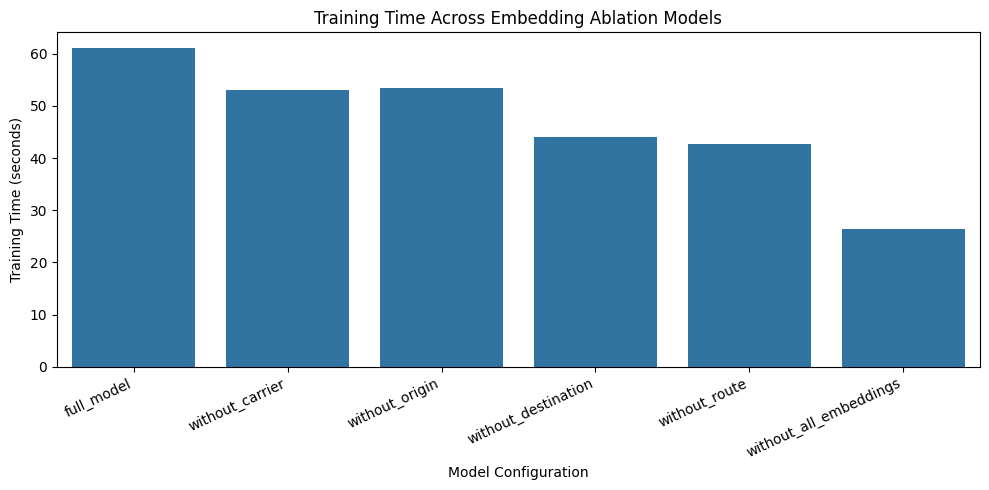

In [43]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ablation_df,
    x="Experiment",
    y="Training Time (seconds)"
)

plt.title("Training Time Across Embedding Ablation Models")
plt.xlabel("Model Configuration")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    "comparison_plots/ablation_training_time.png",
    dpi=300
)

plt.show()

## 12. Inference Time Comparison

Inference time measures the time required for a trained model to generate predictions on the test dataset.

The same test observations and batch size are used across the ablation configurations. A warm-up pass is performed before timing to reduce first-run overhead.

Inference time is reported in seconds and milliseconds per observation.

In [44]:
def measure_inference_time(model, loader, feature_indices):

    model.eval()

    # Warm-up
    with torch.no_grad():
        for x_num, x_cat, y in loader:
            x_num = x_num.to(device)
            x_cat = x_cat[:, feature_indices].to(device)
            model(x_num, x_cat)
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    total_rows = 0

    with torch.no_grad():
        for x_num, x_cat, y in loader:
            x_num = x_num.to(device)
            x_cat = x_cat[:, feature_indices].to(device)

            model(x_num, x_cat)
            total_rows += len(y)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return elapsed, elapsed * 1000 / total_rows


inference_results = []

for name, retained_features in experiments.items():

    feature_indices = [
        all_features.index(f)
        for f in retained_features
    ]

    category_sizes = {
        f: checkpoint["category_sizes"][f]
        for f in retained_features
    }

    embedding_dims = {
        f: checkpoint["embedding_dims"][f]
        for f in retained_features
    }

    model = AblationFlightDelayMLP(
        checkpoint["numerical_input_dim"],
        category_sizes,
        embedding_dims,
        checkpoint["hidden_dims"],
        checkpoint["dropout_rates"]
    ).to(device)

    state = torch.load(
        f"project_inputs/evaluation/ablation_checkpoints/{name}.pth",
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state)

    loader = DataLoader(
        test_dataset,
        batch_size=512,
        shuffle=False
    )

    total_time, ms_per_row = measure_inference_time(
        model, loader, feature_indices
    )

    inference_results.append({
        "Experiment": name,
        "Inference Time (seconds)": total_time,
        "Milliseconds per Observation": ms_per_row
    })

inference_df = pd.DataFrame(inference_results)

inference_df.to_csv(
    "project_inputs/evaluation/inference_time_comparison.csv",
    index=False
)

display(inference_df)

,Experiment,Inference Time (seconds),Milliseconds per Observation
0,full_model,0.458358,0.008490
1,without_carrier,0.392278,0.007266
2,without_origin,0.886509,0.016420
3,without_destination,0.425117,0.007874
4,without_route,0.445587,0.008253
5,without_all_embeddings,0.381903,0.007073


## 13. Visualisation of Embedding Ablation Results

The ablation experiments are visualised to compare predictive performance and model complexity.

PR-AUC, ROC-AUC and F1-score are used to examine predictive performance, while parameter count and training time provide computational context.

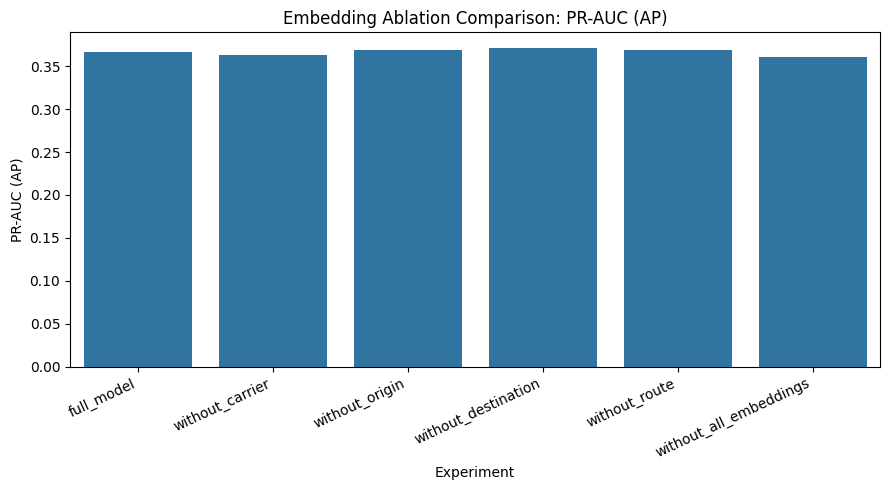

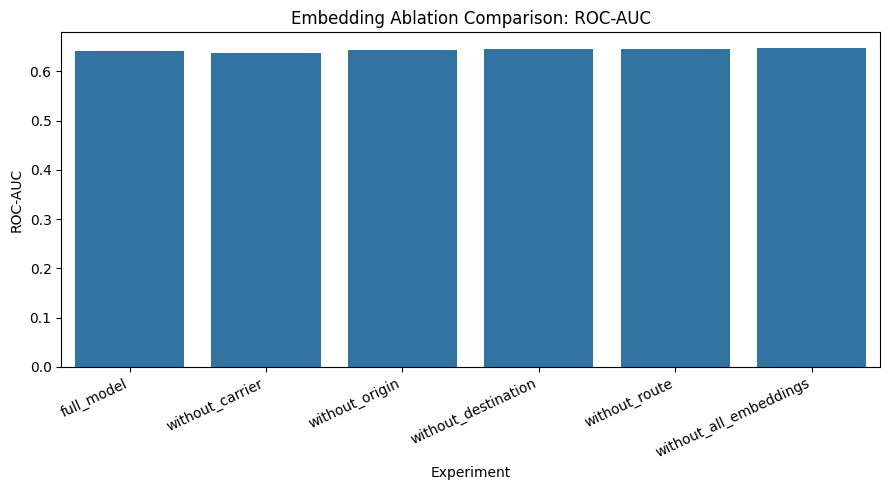

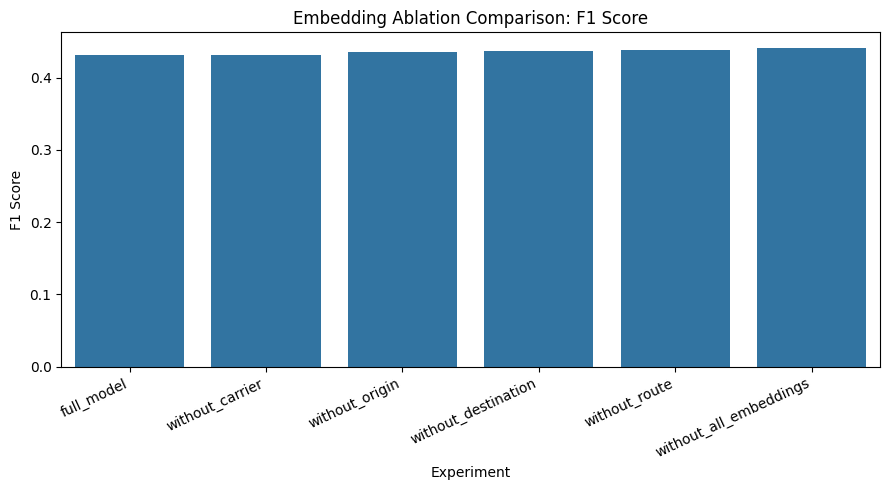

In [45]:
plot_metrics = [
    "PR-AUC (AP)",
    "ROC-AUC",
    "F1 Score"
]

for metric in plot_metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=ablation_df,
        x="Experiment",
        y=metric
    )

    plt.title(f"Embedding Ablation Comparison: {metric}")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()

    plt.savefig(
        f"comparison_plots/ablation_{metric.replace(' ', '_')}.png",
        dpi=300
    )

    plt.show()

## 14. Computational Complexity: AML vs Deep Learning

The computational characteristics of Logistic Regression, XGBoost and the Embedding MLP are compared.

The Deep Learning model is described using trainable parameter count, training time and inference time.

Logistic Regression and XGBoost are described using their available model-specific complexity measures.

The comparison considers predictive performance alongside computational requirements rather than relying on a single complexity measure.

In [46]:
print("Deep Learning model complexity")
print("Full model trainable parameters:", 43142)

print("\nAblation model complexity")
display(
    ablation_df[
        ["Experiment", "Trainable Parameters",
         "Training Time (seconds)"]
    ]
)

print("\nInference time")
display(inference_df)

Deep Learning model complexity
Full model trainable parameters: 43142

Ablation model complexity


,Experiment,Trainable Parameters,Training Time (seconds)
0,full_model,43142,61.043064
1,without_carrier,41837,53.092173
2,without_origin,42878,53.441755
3,without_destination,31592,44.007566
4,without_route,25792,42.644414
5,without_all_embeddings,12673,26.337202



Inference time


,Experiment,Inference Time (seconds),Milliseconds per Observation
0,full_model,0.458358,0.008490
1,without_carrier,0.392278,0.007266
2,without_origin,0.886509,0.016420
3,without_destination,0.425117,0.007874
4,without_route,0.445587,0.008253
5,without_all_embeddings,0.381903,0.007073


## 15. Strengths and Limitations of AML and Deep Learning Models

The comparison shows different performance characteristics across the models.

The Embedding MLP achieves the highest PR-AUC and F1-score among the three models in the current comparison. This suggests stronger performance in identifying the minority delayed-flight class under the reported evaluation procedure.

XGBoost achieves the highest ROC-AUC, indicating stronger overall ranking discrimination in this comparison.

Logistic Regression provides a simpler traditional baseline, while XGBoost offers a tree-based approach capable of modelling nonlinear relationships.

The Embedding MLP can learn dense representations of categorical variables such as carrier, origin, destination and route. However, it introduces additional training complexity and requires careful tuning.

The conclusions are limited by the evaluation setup, threshold selection, computational environment and availability of calibration results. The Brier Score comparison must be completed before drawing conclusions about relative calibration quality.

In [47]:
display(comparison_df)

print("DL trainable parameters:", 43142)

print("\nEmbedding ablation results:")
display(ablation_df)

print("\nInference time results:")
display(inference_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Brier Score
0,Logistic Regression,0.617800,0.218036,0.595127,0.319147,0.650957,0.235002,NaN
1,XGBoost,0.700582,0.243226,0.468530,0.320219,0.661729,0.265836,NaN
2,Embedding + MLP,0.532830,0.309938,0.708939,0.431312,0.637669,0.361152,0.181063


DL trainable parameters: 43142

Embedding ablation results:


,Experiment,Retained embeddings,PR-AUC (AP),ROC-AUC,Precision,Recall,F1 Score,Brier Score,Threshold,Best Epoch,Validation Loss,Training Time (seconds),Trainable Parameters
0,full_model,"carrier, origin, dest, route",0.366796,0.641671,0.320972,0.658835,0.431652,0.181535,0.181242,7,0.414949,61.043064,43142
1,without_carrier,"origin, dest, route",0.362738,0.637438,0.298502,0.781055,0.431930,0.181613,0.155606,7,0.415956,53.092173,41837
2,without_origin,"carrier, dest, route",0.368949,0.643161,0.308644,0.741254,0.435821,0.182390,0.150805,7,0.415160,53.441755,42878
3,without_destination,"carrier, origin, route",0.370848,0.645103,0.302387,0.786985,0.436901,0.181688,0.141867,5,0.414032,44.007566,31592
4,without_route,"carrier, origin, dest",0.369092,0.645217,0.316755,0.709976,0.438067,0.181394,0.164811,4,0.414029,42.644414,25792
5,without_all_embeddings,NaN,0.360562,0.646958,0.321229,0.702194,0.440805,0.181958,0.162329,2,0.413216,26.337202,12673



Inference time results:


,Experiment,Inference Time (seconds),Milliseconds per Observation
0,full_model,0.458358,0.008490
1,without_carrier,0.392278,0.007266
2,without_origin,0.886509,0.016420
3,without_destination,0.425117,0.007874
4,without_route,0.445587,0.008253
5,without_all_embeddings,0.381903,0.007073


## 16. Final Findings and Conclusion

This study compared Logistic Regression, XGBoost and a Deep Learning Embedding MLP for flight delay prediction.

The current model comparison indicates that the Embedding MLP achieves the highest PR-AUC and F1-score, while XGBoost achieves the highest ROC-AUC.

The Embedding MLP uses learned categorical representations for carrier, origin, destination and route. The ablation experiments evaluate the contribution of these embeddings by removing them individually and collectively.

Model complexity is considered using trainable parameter count, training time and inference time. The full Embedding MLP contains 43,142 trainable parameters.

The final assessment considers predictive performance, categorical representation learning and computational cost together. The preferred model depends on the operational objective, including the importance of identifying delayed flights, ranking risk and computational efficiency.

The conclusions are based on the reported test-set results and the completed ablation experiments.

In [48]:
os.makedirs("comparison_results", exist_ok=True)

comparison_df.to_csv(
    "comparison_results/aml_vs_dl_final_comparison.csv",
    index=False
)

ablation_df.to_csv(
    "comparison_results/embedding_ablation_results.csv",
    index=False
)

inference_df.to_csv(
    "comparison_results/inference_time_comparison.csv",
    index=False
)

print("Final comparison files saved.")

print("\nAML vs DL comparison:")
display(comparison_df)

print("\nEmbedding ablation:")
display(ablation_df)

print("\nInference time:")
display(inference_df)

Final comparison files saved.

AML vs DL comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Brier Score
0,Logistic Regression,0.617800,0.218036,0.595127,0.319147,0.650957,0.235002,NaN
1,XGBoost,0.700582,0.243226,0.468530,0.320219,0.661729,0.265836,NaN
2,Embedding + MLP,0.532830,0.309938,0.708939,0.431312,0.637669,0.361152,0.181063



Embedding ablation:


,Experiment,Retained embeddings,PR-AUC (AP),ROC-AUC,Precision,Recall,F1 Score,Brier Score,Threshold,Best Epoch,Validation Loss,Training Time (seconds),Trainable Parameters
0,full_model,"carrier, origin, dest, route",0.366796,0.641671,0.320972,0.658835,0.431652,0.181535,0.181242,7,0.414949,61.043064,43142
1,without_carrier,"origin, dest, route",0.362738,0.637438,0.298502,0.781055,0.431930,0.181613,0.155606,7,0.415956,53.092173,41837
2,without_origin,"carrier, dest, route",0.368949,0.643161,0.308644,0.741254,0.435821,0.182390,0.150805,7,0.415160,53.441755,42878
3,without_destination,"carrier, origin, route",0.370848,0.645103,0.302387,0.786985,0.436901,0.181688,0.141867,5,0.414032,44.007566,31592
4,without_route,"carrier, origin, dest",0.369092,0.645217,0.316755,0.709976,0.438067,0.181394,0.164811,4,0.414029,42.644414,25792
5,without_all_embeddings,NaN,0.360562,0.646958,0.321229,0.702194,0.440805,0.181958,0.162329,2,0.413216,26.337202,12673



Inference time:


,Experiment,Inference Time (seconds),Milliseconds per Observation
0,full_model,0.458358,0.008490
1,without_carrier,0.392278,0.007266
2,without_origin,0.886509,0.016420
3,without_destination,0.425117,0.007874
4,without_route,0.445587,0.008253
5,without_all_embeddings,0.381903,0.007073


In [49]:
import os, shutil
from google.colab import files

os.makedirs("comparison_results/plots", exist_ok=True)
for plot_file in os.listdir("comparison_plots"):
    shutil.copy(f"comparison_plots/{plot_file}", f"comparison_results/plots/{plot_file}")

zip_path = shutil.make_archive("AML_DL_Comparison_Results", "zip", "comparison_results")
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>